***Quantum Algorithms Term Project Fall 2026 - Brianna Kinkaid***

**Import packages**

In [1]:
import pennylane as qp
import numpy as np
import matplotlib.pyplot as plt

**Backward Euler Method**

In [2]:
h_values = [1, 0.1, 0.01] 

all_results = {}
all_times = {}
all_exact = {}


In [ ]:
for h in h_values:

    t = np.arange(0, 20 + h, h)

    M = np.array([
        [1, -h],
        [h, 1]
    ])

    y = np.array([1.0, 0.0])
    results = [y.copy()]

    for n in range(len(t) - 1):
        y = np.linalg.solve(M, y)
        results.append(y.copy())

    results = np.array(results)

    exact = np.cos(t)

    all_results[h] = results
    all_times[h] = t
    all_exact[h] = exact

exact = np.cos(t)

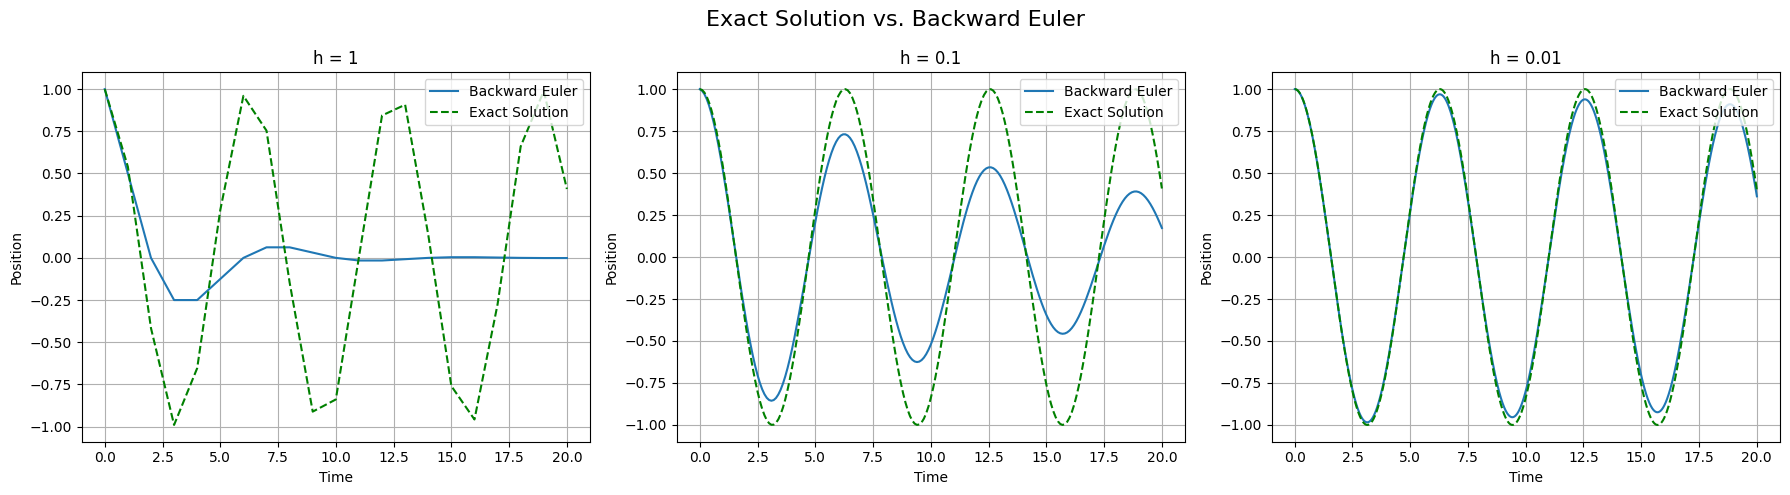

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, h in enumerate(h_values):

    axes[i].plot(
            all_times[h],
            all_results[h][:, 0], 
            label="Backward Euler"
        )

    axes[i].plot(
        all_times[h],
        all_exact[h], "--",
        label="Exact Solution",
        color = "green"
    )

    axes[i].set_xlabel("Time")
    axes[i].set_ylabel("Position")
    axes[i].set_title(f"h = {h}")
    axes[i].legend(loc = "upper right")
    axes[i].grid()

fig.suptitle("Exact Solution vs. Backward Euler", fontsize=16)

plt.tight_layout()
plt.show()

**HHL Quantum Algorithm**

HHL algorithm (single time value)

In [ ]:
h = 0.01

def quantum_backward_euler_step(y, h):

    M = np.array([
        [1.0, -h],
        [h, 1.0]
    ])

    H = np.block([
        [np.zeros((2, 2)), M],
        [M.T, np.zeros((2, 2))]
    ])

    b = np.array([y[0], y[1], 0.0, 0.0])
    b_state = b / np.linalg.norm(b)

    eigenvalues, eigenvectors = np.linalg.eigh(H)

    C = 0.8 * np.min(np.abs(eigenvalues))

    dev = qp.device("default.qubit", wires=3)

    @qp.qnode(dev)
    def HHL_circuit():

        qp.StatePrep(b_state, wires=[0, 1])

        qp.QubitUnitary(eigenvectors.conj().T, wires=[0, 1])

        for j, lam in enumerate(eigenvalues):

            theta = 2 * np.arcsin(C / lam)

            control_values = [(j >> 1) & 1, j & 1]

            qp.ctrl(qp.RY, control=[0, 1], control_values=control_values)(theta, wires=2)

        qp.QubitUnitary(eigenvectors, wires=[0, 1])

        return qp.state()

    quantum_state = HHL_circuit()

    state_reshaped = quantum_state.reshape(4, 2)

    solution_branch = state_reshaped[:, 1]

    solution_part = solution_branch[2:4]

    solution_part = solution_part / np.linalg.norm(solution_part)

    solution_norm = np.linalg.norm(y) / np.sqrt(1 + h**2)

    y_next = np.real_if_close(solution_part * solution_norm).real

    return y_next

y = np.array([1.0, 0.0])

y_next = quantum_backward_euler_step(y, h)

print(y_next)


[ 0.99990001 -0.009999  ]


HHL algorithm (multiple time steps)

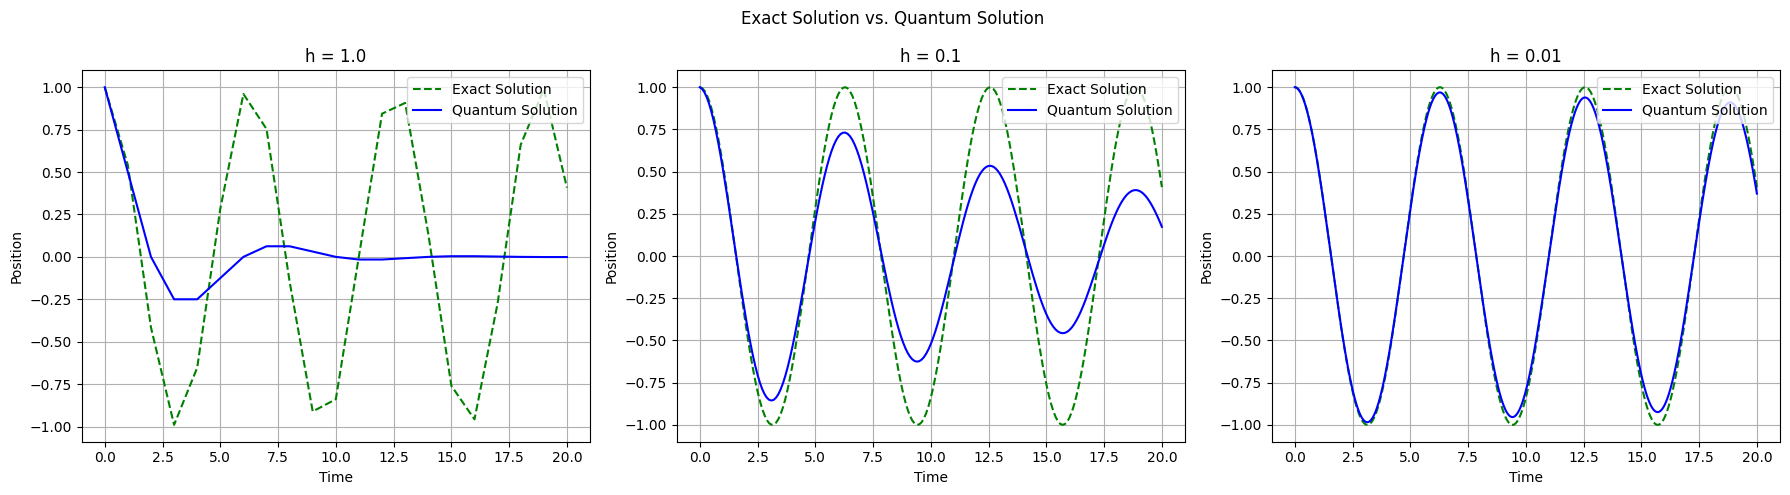

In [ ]:
h_values = [1.0, 0.1, 0.01]

T = 20.0

quantum_results = {}
time_results = {}

for h in h_values:

    number_steps = int(round(T / h))
    t = np.arange(number_steps + 1) * h

    y = np.array([1.0, 0.0])

    position = [y[0]]

    for n in range(number_steps):

        y = quantum_backward_euler_step(y, h)

        position.append(y[0])

    quantum_results[h] = np.array(position)
    time_results[h] = t


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, h in enumerate(h_values):

    t = time_results[h]

    exact_solution = np.cos(t)

    quantum_solution = quantum_results[h]

    axes[i].plot(
        t,
        exact_solution,
        color="green",
        linestyle="--",
        label="Exact Solution"
    )

    axes[i].plot(
        t,
        quantum_solution,
        color="blue",
        linestyle="-",
        label="Quantum Solution"
    )

    axes[i].set_xlabel("Time")
    axes[i].set_ylabel("Position")
    axes[i].set_title(f"h = {h}")
    axes[i].legend(loc = "upper right")
    axes[i].grid(True)

plt.suptitle("Exact Solution vs. Quantum Solution ")
plt.tight_layout()
plt.show()
